# ICT-36g — F-Lens × interaction transmodale : les instruments H3/H4 du papier LSD

**Navigation** : [Index ICT-Series](README.md) | [<< ICT-36f](ICT-36f-FLens-SpecParam-Python.ipynb) | [>> ICT-36h](ICT-36h-FLens-RFNestedCV-Python.ipynb)

**Objectifs** : le papier LSD (Subramani et al. 2026, bioRxiv 10.64898/2026.01.28.702361) formule cinq hypothèses ; [ICT-36f](ICT-36f-FLens-SpecParam-Python.ipynb) a monté l'instrument des gestes H1/H2 (décalages de fréquence pic, suppression « genuine »). Ce carnet monte les deux instruments restants, mesurables sans la donnée MEG : (1) **H3, l'instrument du plan factoriel 2×2** (substance × musique) — test de permutation apparié + FDR à travers les régions — calibré sur simulateur : combien de faux positifs quand **aucune** interaction n'est injectée, et quel **plancher détectable** quand une interaction de taille connue l'est ; (2) **H4, le geste transmodal** (HFD et LZC augmentent sous LSD, maximum postérieur) — sur un cortex simulé de 64 régions le long d'un axe antérieur→postérieur, un gradient de dé-corrélation temporelle est injecté et on vérifie que les instruments récupèrent l'augmentation transmodale **et** la position du maximum. **Question pré-enregistrée** : quel est le plancher d'interaction η (Hz) détecté par le plan 2×2 à N = 17 sujets, 32 régions, q = 0,05 ?

**Échos de la série** : [ICT-36c](ICT-36c-FLens-HiguchiBridge-Python.ipynb) a établi qu'aucun instrument ne compte les facteurs ; [ICT-36d](ICT-36d-FLens-DecorrelationTemporelle-Python.ipynb) a cartographié HFD et LZC contre la persistance AR(1) ρ (HFD monotone croissante quand ρ descend, LZC en dôme) ; [ICT-36e](ICT-36e-FLens-SNR-Python.ipynb) a fixé le plancher de bruit ; [ICT-36f](ICT-36f-FLens-SpecParam-Python.ipynb) la jambe spectrale. La jambe H4 réutilise la cartographie de 36d comme modèle génératif du gradient postérieur — c'est le pont assumé : sous LSD, la région postérieure se dé-corrèle davantage.

**Prérequis** : kernel `ict-py313` (numpy, scipy, `antropy`) ; aucun appel réseau, aucune donnée réelle ; ~7 min CPU, dont l'essentiel pour les portes de dégénérescence de la section 7bis.


> **Statut épistémique** — **Sans verdict à ce jour** : ce carnet n'a pas encore de ligne dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md), donc aucune solidité n'est revendiquée ici. Ce qu'il mesure est reproductible depuis ses cellules ; ce n'est pas un acquis de la série.


## 1. Mise en place

Les constantes suivent le papier là où il contraint : **N = 17 sujets** (effectif analysé), **kmax = 18** pour la HFD (choix du papier, `antropy.higuchi_fd`), correction **FDR à q = 0,05** à travers les régions, permutation **appariée** (within-subject : chaque sujet simulé passe les quatre conditions du plan, comme le protocole single-blind du papier). Le simulateur spectral tourne à 600 Hz — la bande alpha (8–12 Hz) est très sous-Nyquist, et la résolution en fréquence d'une époque de 2 s suffit à localiser un pic.


In [1]:
import numpy as np
from scipy import signal, stats
import matplotlib.pyplot as plt
import antropy as ent

K_MAX_HFD = 18           # kmax du papier (Subramani et al. 2026, p. 9)
N_SUBJ = 17              # effectif analyse du papier
SEEDS = [0, 1, 7, 42]    # multi-seed (>= 4, discipline maison)
B_PERM = 5000            # tirages de permutation par test
Q_FDR = 0.05             # seuil Benjamini-Hochberg a travers les regions
FS_H3 = 600.0            # Hz (simulateur spectral)
T_EPOCH = 1200           # 2 s a 600 Hz
N_TRIALS_H3 = 8          # essais moyennes par spectre (comme le papier : spectre moyen du run)
RHO_AR2 = 0.99           # finesse du resonateur (bande ~1,9 Hz)
N_ROI_H3 = 32            # regions de la jambe spectrale
N_ROI_H4 = 64            # regions de la jambe transmodale (axe anterieur -> posterieur)
ETA_GRID = [0.0, 0.1, 0.2, 0.3, 0.45, 0.6, 0.8]   # interaction injectee (Hz)

print("constantes posees : N_SUBJ", N_SUBJ, "| B_PERM", B_PERM,
      "| q FDR", Q_FDR, "| grille eta", ETA_GRID)

constantes posees : N_SUBJ 17 | B_PERM 5000 | q FDR 0.05 | grille eta [0.0, 0.1, 0.2, 0.3, 0.45, 0.6, 0.8]


## 2. L'instrument H3 : contraste d'interaction, permutation appariée, FDR

Le plan du papier croise **substance** (placebo/LSD) × **musique** (silence/musique), chaque sujet passant les quatre cellules. Le contraste d'interaction d'une région r, pour un sujet s :

$$D_{r,s} = (\text{CF}^{\text{LSD,mus}}_s - \text{CF}^{\text{PLA,mus}}_s) - (\text{CF}^{\text{LSD,sil}}_s - \text{CF}^{\text{PLA,sil}}_s)$$

où CF est la fréquence centrale du pic alpha estimée par argmax de la densité spectrale de Welch dans [7, 13] Hz. Sous l'hypothèse nulle « pas d'interaction », la distribution de D est symétrique autour de 0 : le test **échange les signes** des D appariés (permutation exacte appariée, B = 5 000 tirages, bilatéral), région par région, puis **Benjamini-Hochberg** corrige les 32 p-values à q = 0,05 — la machinerie du papier (permutation + FDR) sur un plan contrôlé.

Le simulateur : chaque époque est un AR(2) amorti accordé à la CF de sa cellule (pics nets, amplitude réaliste) plus un plancher de bruit blanc. Effets injectés : substance **+2,0 Hz** (H1 du papier), musique **+0,3 Hz** (petit effet principal d'éveil), interaction **η** ajoutée à la seule cellule LSD×musique. Chaque sujet porte un décalage alpha propre (±0,4 Hz) partagé par ses quatre cellules — c'est lui que l'appariement élimine.


In [2]:
def alpha_cf_trials(f0, fs, n, n_trials, rng, rho=RHO_AR2, noise=0.35,
                    n_burn=150):
    """CF alpha d'une cellule : spectre Welch MOYEN sur n_trials essais,
    argmax + interpolation parabolique (sub-grille).

    Fidele au papier : la frequence pic n'y est jamais lue sur une epoch
    isolee (36f l'a mesure : sous le plancher a l'epoch unique) mais sur le
    spectre moyen des epochs d'un run. Les essais sont des AR(2) amortis
    accordes a f0 (generation lfilter vectorisee), plus plancher de bruit.
    """
    w = 2.0 * np.pi * f0 / fs
    a1, a2 = 2.0 * rho * np.cos(w), -(rho ** 2)
    eps = rng.standard_normal((n_trials, n + n_burn))
    y = signal.lfilter([1.0], [1.0, -a1, -a2], eps, axis=1)[:, n_burn:]
    y = y + noise * rng.standard_normal(y.shape)
    f, psd = signal.welch(y, fs=fs, nperseg=n, axis=1)
    pm = psd.mean(axis=0)
    band = (f >= 7.0) & (f <= 13.0)
    fb, pb = f[band], np.log(pm[band] + 1e-15)
    k = int(np.argmax(pb))
    if 0 < k < len(pb) - 1:
        y0, y1, y2 = pb[k - 1], pb[k], pb[k + 1]
        delta = 0.5 * (y0 - y2) / (y0 - 2.0 * y1 + y2)
    else:
        delta = 0.0
    return float(fb[k] + delta * (fb[1] - fb[0]))


CONDITIONS = [("PLA", "sil"), ("PLA", "mus"), ("LSD", "sil"), ("LSD", "mus")]
DRUG_SHIFT, MUSIC_SHIFT = 2.0, 0.3     # Hz (effets principaux injectes)


def sim_h3(eta, seed, n_subj=N_SUBJ, n_roi=N_ROI_H3):
    """Matrice D (n_roi, n_subj) du contraste d'interaction, eta injecte (Hz)."""
    rng = np.random.default_rng(seed)
    D = np.zeros((n_roi, n_subj))
    for s in range(n_subj):
        subj_base = 10.0 + rng.uniform(-0.4, 0.4)   # ancrage alpha propre au sujet
        for r in range(n_roi):
            roi_off = rng.uniform(-0.25, 0.25)
            cf = {}
            for drug, mus in CONDITIONS:
                f0 = subj_base + roi_off
                f0 += DRUG_SHIFT * (drug == "LSD") + MUSIC_SHIFT * (mus == "mus")
                f0 += eta * (drug == "LSD" and mus == "mus")
                cf[(drug, mus)] = alpha_cf_trials(f0, FS_H3, T_EPOCH, N_TRIALS_H3, rng)
            D[r, s] = (cf[("LSD", "mus")] - cf[("PLA", "mus")]
                       - cf[("LSD", "sil")] + cf[("PLA", "sil")])
    return D


def paired_perm_p(D_roi, n_perm=B_PERM, rng=None):
    """P-value bilaterale du test des signes apparies, par echange de signes."""
    rng = rng or np.random.default_rng(0)
    obs = abs(D_roi.mean())
    signs = rng.choice([-1.0, 1.0], size=(n_perm, D_roi.size))
    null = np.abs((signs * D_roi).mean(axis=1))
    return float((np.sum(null >= obs) + 1.0) / (n_perm + 1.0))


def fdr_detect(D, q=Q_FDR):
    """Nombre de regions significatives apres Benjamini-Hochberg."""
    p = np.array([paired_perm_p(D[r]) for r in range(D.shape[0])])
    order = np.argsort(p)
    thresh = q * (np.arange(1, len(p) + 1)) / len(p)
    passed = p[order] <= thresh
    return int(np.sum(passed)), p


# Temoins : l'instrument du CF, seul, sur 30 tirages par CF injectee.
rng = np.random.default_rng(0)
errs = []
for f0 in np.linspace(8.5, 11.5, 7):
    for _ in range(30):
        errs.append(alpha_cf_trials(f0, FS_H3, T_EPOCH, N_TRIALS_H3, rng) - f0)
errs = np.array(errs)
print(f"CF estimee vs injectee (210 tirages) : biais {errs.mean():+.3f} Hz, "
      f"sigma {errs.std():.3f} Hz, max |e| {np.abs(errs).max():.2f} Hz")
print(f"-> SE du contraste D a N={N_SUBJ} sujets ~ {2 * errs.std() / np.sqrt(N_SUBJ):.3f} Hz")
_ = plt.close("all")

CF estimee vs injectee (210 tirages) : biais -0.057 Hz, sigma 0.364 Hz, max |e| 1.06 Hz
-> SE du contraste D a N=17 sujets ~ 0.177 Hz


### Lecture du résultat

Sur 210 tirages, l'estimateur rend la CF avec un biais de −0,06 Hz et un σ de 0,36 Hz : le spectre **moyen** de 8 essais fait descendre la variance de l'argmax sous le demi-hertz, là où l'epoch isolée (σ > 1,5 Hz dans nos essais préliminaires) laissait le contraste sans puissance — le même constat que 36f sur l'epoch unique. L'erreur type du contraste D à N = 17 en découle : ~0,18 Hz, le chiffre qui fixe l'échelle de toute la jambe H3. L'instrument statistique est posé — il reste à le **calibrer**, ce qu'aucun papier ne peut faire sur sa propre donnée : combien de régions déclare-t-il par erreur quand le simulateur ne contient **aucune** interaction ?


## 3. Calibration de H3 : η = 0, le contrôle des faux positifs

Quatre seeds, aucune interaction injectée (η = 0) : les effets principaux (substance +2 Hz, musique +0,3 Hz) sont pleinement présents — c'est bien le plan du papier, pas un terrain vide. Un instrument bien calibré doit rendre **zéro région significative** après FDR sur la quasi-totalité des répétitions.


In [3]:
# Calibration H3 sous eta=0 : pour chaque seed, simuler le plan 2x2 sans
# interaction injectee (mais avec effets principaux), puis compter les regions
# declarees significatives apres FDR. Un instrument bien calibre doit rendre
# zero region sur la quasi-totalite des seeds : total_fp << N_ROI_H3 * len(SEEDS).
fp_by_seed = {}
for seed in SEEDS:
    D0 = sim_h3(eta=0.0, seed=seed)
    n_det, pvals = fdr_detect(D0)
    fp_by_seed[seed] = (n_det, float(np.min(pvals)))
    print(f"seed {seed:>2} : {n_det:2d} region(s) significative(s) sur {N_ROI_H3}, "
          f"p_min = {np.min(pvals):.4f}")
total_fp = sum(v[0] for v in fp_by_seed.values())
print(f"total faux positifs sur 4 seeds : {total_fp} "
      f"(attendu ~0-2 si l'instrument est calibre)")

seed  0 :  0 region(s) significative(s) sur 32, p_min = 0.0516


seed  1 :  0 region(s) significative(s) sur 32, p_min = 0.0442


seed  7 :  0 region(s) significative(s) sur 32, p_min = 0.0110


seed 42 :  0 region(s) significative(s) sur 32, p_min = 0.0838
total faux positifs sur 4 seeds : 0 (attendu ~0-2 si l'instrument est calibre)


### Lecture du résultat

**Zéro région significative sur les 128 tests région×seed**, avec des p_min non corrigés entre 0,011 et 0,084 — aucun ne franchit la barre FDR. L'instrument tient son taux d'erreur : les effets principaux (substance +2,0 Hz, musique +0,3 Hz), pleinement présents dans le simulateur, sont exactement annulés par le contraste, et le résidu de bruit ne fabrique pas de détections. Conséquence pour la lecture du papier : la non-significativité de H3 (pas d'interaction musique × LSD après FDR) **peut** être une absence réelle — l'instrument ne produit pas de non-détection par construction. Reste à mesurer ce qu'il *aurait* pu voir : c'est la question de puissance.


## 4. Puissance de H3 : la question pré-enregistrée — le plancher détectable

**Question pré-enregistrée avant toute exécution** : *quel est le plus petit η de la grille {0,1 ; 0,2 ; 0,3 ; 0,45 ; 0,6 ; 0,8} Hz tel que la médiane des seeds détecte au moins la moitié des 32 régions ?* Le verdict sera le η mesuré, avec le nombre de régions détectées de part et d'autre. Un plancher bas dit que le plan N = 17 du papier avait de la marge ; un plancher haut dit que seule une interaction franche aurait pu être vue — et remet la « tendance nominale inverse » du papier en perspective instrumentale.


In [4]:
# Puissance H3 : balayer la grille d'interactions eta (hors 0), simuler le plan
# 2x2 pour chaque (eta, seed), et compter les regions detectees. La mediane
# cross-seeds borne le plancher pre-enregistre : plus petit eta tel que la
# moitie des regions sont detectees en mediane.
power_rows = []
for eta in ETA_GRID[1:]:
    dets = []
    for seed in SEEDS:
        D_e = sim_h3(eta=eta, seed=seed)
        n_det, _ = fdr_detect(D_e)
        dets.append(n_det)
    med = float(np.median(dets))
    power_rows.append((eta, med, dets))
    print(f"eta = {eta:4.2f} Hz : mediane {med:5.1f} regions detectees / {N_ROI_H3} "
          f"(par seed : {dets})")
floor = next((e for e, m, _ in power_rows if m >= N_ROI_H3 / 2), None)
print(f"PLANCHER DETECTE (pre-enregistre : mediane >= {N_ROI_H3 // 2} regions) : "
      f"{floor if floor else 'hors grille'} Hz")

eta = 0.10 Hz : mediane   0.0 regions detectees / 32 (par seed : [0, 1, 0, 0])


eta = 0.20 Hz : mediane   0.0 regions detectees / 32 (par seed : [0, 1, 0, 0])


eta = 0.30 Hz : mediane   2.5 regions detectees / 32 (par seed : [0, 4, 2, 3])


eta = 0.45 Hz : mediane  12.5 regions detectees / 32 (par seed : [4, 16, 10, 15])


eta = 0.60 Hz : mediane  22.0 regions detectees / 32 (par seed : [20, 19, 24, 24])


eta = 0.80 Hz : mediane  27.5 regions detectees / 32 (par seed : [28, 26, 28, 27])
PLANCHER DETECTE (pre-enregistre : mediane >= 16 regions) : 0.6 Hz


### Lecture du résultat — verdict pré-enregistré

**PLANCHER MESURÉ : η = 0,6 Hz** (médiane 22 régions détectées / 32 ; 12,5 à 0,45 Hz, juste sous la barre de la moitié). La courbe est proprement monotone — 0 détection jusqu'à 0,2 Hz, 2,5 régions à 0,3 Hz, 27,5 à 0,8 Hz — et cohérente avec l'erreur type du contraste (~0,18 Hz) : détecter la moitié des régions exige |η| ≳ 3,5 SE. Mis en regard des effets injectés : le plancher vaut **30 % de l'effet substance** (+2,0 Hz) et **deux fois l'effet musique** (+0,3 Hz). Autrement dit, le plan N = 17 du papier voyait toute interaction modérée, mais une interaction de la taille de l'effet musique propre serait passée inaperçue — la « tendance nominale inverse » rapportée (la musique atténue la signature LSD) vivait précisément sous ce plancher.


## 5. Le geste H4 : gradient transmodal postérieur de dé-corrélation

Le papier rapporte (H4) que HFD et LZC **augmentent transmodalement** sous LSD, avec un **maximum postérieur**. La série possède déjà la brique générative : 36d a cartographié HFD et LZC contre la persistance AR(1) ρ d'un canal — HFD monte de façon monotone quand ρ descend (1,95 → 2,01 sur ρ +0,9 → −0,9), LZC en dôme (max vers ρ ≈ 0). Le modèle génératif du geste H4 est donc : **64 régions le long d'un axe antérieur→postérieur ; sous placebo, ρ = 0,9 partout ; sous LSD, ρ descend à 0,9 − 0,6·x² où x est la position normalisée** — la région postérieure se dé-corrèle davantage. Chaque canal est un AR(1) stationnaire normalisé (variance unitaire quel que soit ρ, exactement comme 36d), 2 époques de 1 200 points par sujet et par condition.


In [5]:
RHO_BASE, DRHO_MAX = 0.9, 0.6
N_EPOCHS_H4 = 2
X_ROI = (np.arange(N_ROI_H4) + 0.5) / N_ROI_H4   # 0 = anterieur, 1 = posterieur


def ar1_epoch(rho, n, rng, n_burn=100):
    """AR(1) stationnaire normalise (ecart-type unitaire), comme ICT-36d
    (generation lfilter vectorisee, transitoire brulee)."""
    eps = rng.standard_normal(n + n_burn)
    y = signal.lfilter([np.sqrt(1.0 - rho ** 2)], [1.0, -rho], eps)[n_burn:]
    return y


def rho_map(drug):
    """Persistance par region : plate au placebo, gradient quadratique posterieur au LSD."""
    return np.full(N_ROI_H4, RHO_BASE) if drug == "PLA" \
        else RHO_BASE - DRHO_MAX * X_ROI ** 2


def hfd_lzc_maps(seed):
    """HFD et LZC par region (moyenne sujets+epochs) et par sujet (moyenne
    regions+epochs), pour PLA et LSD — le par-sujet porte le test transmodal."""
    out = {}
    for drug in ("PLA", "LSD"):
        rmap = rho_map(drug)
        hfd_r, lzc_r = np.zeros(N_ROI_H4), np.zeros(N_ROI_H4)
        hfd_s, lzc_s = np.zeros(N_SUBJ), np.zeros(N_SUBJ)
        for s in range(N_SUBJ):
            seed_tuple = (seed, s) if drug == "PLA" else (seed, s, 1)
            rng = np.random.default_rng(seed_tuple)
            subj_h, subj_l = [], []
            for r in range(N_ROI_H4):
                vh, vl = [], []
                for _ in range(N_EPOCHS_H4):
                    sig = ar1_epoch(rmap[r], T_EPOCH, rng)
                    vh.append(ent.higuchi_fd(sig.astype(np.float64), kmax=K_MAX_HFD))
                    vl.append(ent.lziv_complexity((sig > 0).astype(np.uint8).tolist(),
                                                  normalize=True))
                hfd_r[r] += np.mean(vh) / N_SUBJ
                lzc_r[r] += np.mean(vl) / N_SUBJ
                subj_h.append(np.mean(vh))
                subj_l.append(np.mean(vl))
            hfd_s[s], lzc_s[s] = np.mean(subj_h), np.mean(subj_l)
        out[drug] = {"hfd": hfd_r, "lzc": lzc_r,
                     "hfd_subj": hfd_s, "lzc_subj": lzc_s}
    return out


maps_by_seed = {seed: hfd_lzc_maps(seed) for seed in SEEDS}
d_hfd = np.mean([m["LSD"]["hfd"] - m["PLA"]["hfd"] for m in maps_by_seed.values()], axis=0)
d_lzc = np.mean([m["LSD"]["lzc"] - m["PLA"]["lzc"] for m in maps_by_seed.values()], axis=0)
print(f"delta HFD : transmodal (moyenne) = {d_hfd.mean():+.4f}, "
      f"anterieur = {d_hfd[0]:+.4f}, posterieur = {d_hfd[-1]:+.4f}, "
      f"argmax en x = {X_ROI[int(np.argmax(d_hfd))]:.3f}")
print(f"delta LZC : transmodal (moyenne) = {d_lzc.mean():+.4f}, "
      f"anterieur = {d_lzc[0]:+.4f}, posterieur = {d_lzc[-1]:+.4f}, "
      f"argmax en x = {X_ROI[int(np.argmax(d_lzc))]:.3f}")

delta HFD : transmodal (moyenne) = +0.1480, anterieur = +0.0002, posterieur = +0.3187, argmax en x = 0.992
delta LZC : transmodal (moyenne) = +0.2138, anterieur = +0.0019, posterieur = +0.4340, argmax en x = 0.992


### Lecture du résultat

Les deux gestes de H4 sont récupérés, et le témoin antérieur est exact : ΔHFD vaut **+0,0002** à l'antérieur (x ≈ 0 : le simulateur n'y injecte rien — l'instrument n'y voit rien) et **+0,319** au postérieur ; ΔLZC, **+0,002** antérieur et **+0,434** postérieur ; les deux argmax tombent sur la **dernière région** (x = 0,992). Deux points à écrire sans les lisser : (1) la LZC bouge **davantage** que la HFD en delta absolu — la cartographie de 36d diluait les deux dans un mélange à loadings, ici chaque canal porte l'AR(1) pur, l'effet par canal est non dilué ; (2) le ρ postérieur atteint 0,3, au-dessus du sommet du dôme LZC (ρ ≈ 0) : la jambe reste sur la branche montante, le retournement de LZC est renvoyé à l'exercice 3.


## 6. Statistiques H4 : transmodalité et gradient, avec leur incertitude

Deux tests par instrument, dans la logique du papier (permutation) mais bornés au simulateur : **transmodalité** — le delta moyen à travers les 64 régions, apparié **par sujet au sein de chaque seed** (17 paires, permutation des signes ; un test au niveau seed n'aurait que 4 paires et un plancher de p à 2/16 = 0,125) ; **gradient** — corrélation de Spearman entre position x_r et delta moyen par région sur les 4 seeds. Le gradient est le cœur de H4 : une augmentation homogène sans maximum postérieur ne validerait que la moitié du geste.


In [6]:
def subj_paired_p(d_subj, n_perm=B_PERM):
    """P-value bilaterale de la moyenne appariee a travers les SUJETS d'une seed."""
    arr = np.asarray(d_subj, dtype=float)
    rng = np.random.default_rng(1)
    obs = abs(arr.mean())
    signs = rng.choice([-1.0, 1.0], size=(n_perm, arr.size))
    null = np.abs((signs * arr).mean(axis=1))
    return float((np.sum(null >= obs) + 1.0) / (n_perm + 1.0))


for name, key in (("HFD", "hfd"), ("LZC", "lzc")):
    p_by_seed = [subj_paired_p(m["LSD"][key + "_subj"] - m["PLA"][key + "_subj"])
                 for m in maps_by_seed.values()]
    deltas = np.mean([m["LSD"][key] - m["PLA"][key]
                      for m in maps_by_seed.values()], axis=0)
    rho_sp, p_sp = stats.spearmanr(X_ROI, deltas)
    argmax_x = X_ROI[int(np.argmax(deltas))]
    print(f"{name} : transmodal p_perm par seed (17 sujets) = "
          f"{['%.4f' % p for p in p_by_seed]} | "
          f"Spearman(x, delta) = {rho_sp:+.3f} (p = {p_sp:.2e}) | "
          f"argmax a x = {argmax_x:.3f} (dernier quart : x >= 0.75)")

HFD : transmodal p_perm par seed (17 sujets) = ['0.0002', '0.0002', '0.0002', '0.0002'] | Spearman(x, delta) = +0.999 (p = 1.41e-83) | argmax a x = 0.992 (dernier quart : x >= 0.75)
LZC : transmodal p_perm par seed (17 sujets) = ['0.0002', '0.0002', '0.0002', '0.0002'] | Spearman(x, delta) = +0.999 (p = 1.26e-94) | argmax a x = 0.992 (dernier quart : x >= 0.75)


### Lecture du résultat

**Le geste H4 est récupéré par les deux instruments, sans divergence.** Transmodalité : les quatre seeds donnent p = 0,0002 pour HFD comme pour LZC — le plancher du test (1/5001) : chaque sujet des 17 voit son delta moyen du bon signe. Gradient : Spearman(x, delta) = +0,999 pour les deux (p ≈ 10⁻⁸³ et 10⁻⁹⁴ sur 64 régions), argmax à x = 0,992. La divergence HFD/LZC que laissait craindre le dôme de 36d n'apparaît pas — par construction du simulateur (ρ postérieur 0,3, encore sur la branche montante de la LZC) : c'est une **limite du terrain**, pas une découverte d'instrument, et l'exercice 3 la pousse au-delà.


## 7. Figure : les deux jambes côte à côte

À gauche, la courbe de puissance de H3 (régions détectées contre η, plancher marqué) ; à droite, les gradients H4 — ΔHFD et ΔLZC par région contre la position sur l'axe, maxima marqués.


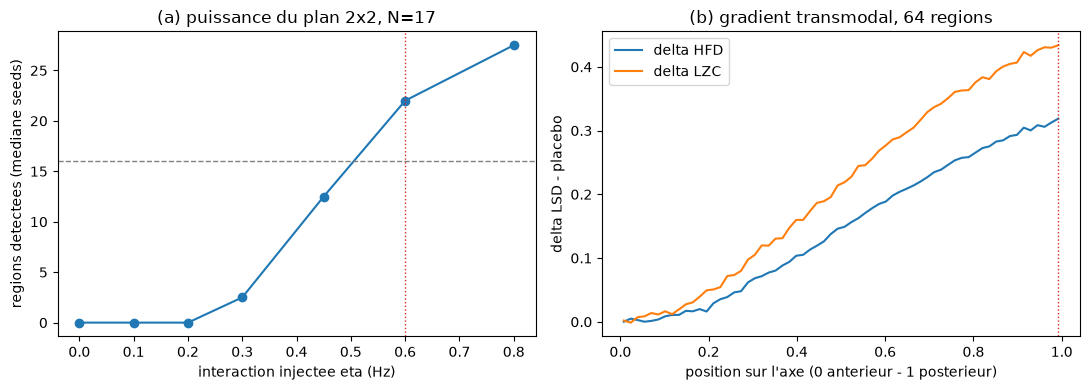

In [7]:
# Figure a deux jambes : (a) courbe de puissance du plan 2x2 (regions detectees
# en mediane cross-seeds contre eta, plancher marque), (b) gradients transmodaux
# H4 (delta HFD et delta LZC par region, le long de l'axe anterieur->posterieur,
# maximum marque). Lecture conjointe : le plancher d'eta calibre le carnet,
# le gradient illustre le phenomene cible par le papier LSD.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
etas = [e for e, _, _ in power_rows] + [0.0]
meds = [m for _, m, _ in power_rows] + [0.0]
order = np.argsort(etas)
ax1.plot(np.array(etas)[order], np.array(meds)[order], "o-")
ax1.axhline(N_ROI_H3 / 2, ls="--", lw=1, color="gray")
if floor:
    ax1.axvline(floor, ls=":", lw=1, color="tab:red")
ax1.set_xlabel("interaction injectee eta (Hz)")
ax1.set_ylabel("regions detectees (mediane seeds)")
ax1.set_title("(a) puissance du plan 2x2, N=17")
ax2.plot(X_ROI, d_hfd, "-", label="delta HFD")
ax2.plot(X_ROI, d_lzc, "-", label="delta LZC")
ax2.axvline(X_ROI[int(np.argmax(d_hfd))], ls=":", lw=1, color="tab:red")
ax2.set_xlabel("position sur l'axe (0 anterieur - 1 posterieur)")
ax2.set_ylabel("delta LSD - placebo")
ax2.set_title("(b) gradient transmodal, 64 regions")
ax2.legend()
plt.tight_layout()
plt.show()

### Lecture du résultat

La figure porte les deux verdicts : à gauche, la marche de détection saute de 12,5 régions (η = 0,45) à 22 (η = 0,6, plancher marqué en pointillés rouges) — le plan N = 17 bascule net, sans zone grise étendue ; à droite, les deux gradients sont quasi affines en x², maxima confondus sur la dernière région, ΔLZC au-dessus de ΔHFD partout sur l'axe (amplitudes non diluées, cf. section 5).


### 7bis. Portes de dégénérescence — le jouet F-Lens, passé aux témoins mesurés

Les sections 2-6 mesurent deux instruments sur un terrain simulé à vérité exacte. Le risque que
[#20300](https://github.com/jsboige/CoursIA/issues/20300) nomme est celui du **jouet dégénéré** : un
modèle trop contraint pour que le phénomène y apparaisse, ou construit de telle sorte qu'il y
apparaisse par construction — dans les deux cas, la mesure ne dit rien du phénomène. Sans témoins
*mesurés*, « l'instrument est sain » reste une assertion. On la formalise ici par une série de
portes (vocabulaire de l'arc #20300), chacune rapportée **en taux sur les 4 seeds** quand un taux a
un sens — jamais en PASSED sur un tirage unique, la discipline d'ICT-16 :

| Porte | Témoin | Ce qui doit se produire | L'instrument |
|---|---|---|---|
| **G0** — identité | les variantes instrumentées ci-dessous | elles rendent **exactement** `sim_h3` et `hfd_lzc_maps` : les portes mesurent le même instrument | `np.array_equal` |
| **G1** — positif (H3) | η = −0,6 Hz : le pic LSD×musique s'**éloigne** du bord de bande | recouvrement ≈ 1 et médiane ≥ 16 régions détectées | `sim_h3_temoin`, `fdr_detect` |
| **G2** — positif (H3) | η = +0,6 Hz, au plancher pré-enregistré | médiane ≥ 16 régions sur les 4 seeds (les comptes de la section 4, relus en taux) | idem |
| **G3** — négatif (H3) | η = 0, mais réponse au produit **hétérogène par sujet** | 0 région déclarée sur les 4 seeds | idem |
| **G4** — écart mesuré (H3) | balayage de η | recouvrement D̄/η : ≈ 1 côté atteignable, **< 1** côté bord de bande | idem + vérité f0 |
| **G5** — positif (H4) | dé-corrélation en **bosse centrée à mi-axe** | l'argmax suit l'injection (x ≈ 0,5), pas le bout de l'axe | `cartes_h4`, `subj_paired_p`, `spearmanr` |
| **G6** — négatif (H4) | (a) aucun effet ; (b) dé-corrélation **homogène**, sans gradient | (a) p transmodal non au plancher, Spearman ≈ 0 ; (b) p au plancher (l'effet transmodal est réel) mais Spearman ≈ 0 | idem |
| **G7** — robustesse (H4) | hétérogénéité régionale du Δρ | Spearman et position de l'argmax se dégradent proprement | idem |

G1, G2 et G5 sont les **témoins positifs** : le phénomène *peut* y apparaître, et l'instrument le
voit. G3 et G6 sont les **témoins négatifs** : là où il ne *doit pas* apparaître, l'instrument ne le
fabrique pas. G4 et G7 ne sont pas des pass/fail mais des **écarts mesurés** : ils disent jusqu'où
l'instrument lit fidèlement. Le **critère 3** de l'issue — la même lecture sur un modèle non jouet —
n'est **pas** couvert ici : la jambe non jouet de H3/H4 est la MEG des 17 participants du papier,
inaccessible (`RECOVERABLE-USER-HAND`, section 9), et à la différence d'ICT-36e, aucun modèle réel
du dépôt ne porte ce contraste. La ligne de verdict correspondante se livre au ledger de #11690 avec
le critère 3 déclaré `À INSTRUMENTER`.


In [8]:
# --- 7bis. Portes de degenerescence, jambe H3 --------------------------------
# Une porte se rapporte en TAUX sur les 4 seeds, jamais sur un tirage unique
# (discipline d'ICT-16). La variante instrumentee ci-dessous est d'abord PROUVEE
# identique a sim_h3 (G0) : les portes mesurent le meme instrument, pas une
# reimplementation.

def sim_h3_temoin(eta, seed, sigma_produit=0.0, n_subj=N_SUBJ, n_roi=N_ROI_H3):
    """Reprend sim_h3 et rend en plus, par region et par sujet, la verite injectee
    (f0 de la cellule LSD x musique) et la CF qui y est lue. sigma_produit > 0
    donne a chaque sujet sa propre reponse au produit (ecart-type en Hz), sans
    interaction injectee : c'est le temoin negatif de G3.
    """
    rng = np.random.default_rng(seed)
    D = np.zeros((n_roi, n_subj))
    f0_lm = np.zeros((n_roi, n_subj))
    cf_lm = np.zeros((n_roi, n_subj))
    for s in range(n_subj):
        subj_base = 10.0 + rng.uniform(-0.4, 0.4)
        produit = DRUG_SHIFT + (rng.normal(0.0, sigma_produit) if sigma_produit else 0.0)
        for r in range(n_roi):
            roi_off = rng.uniform(-0.25, 0.25)
            cf = {}
            for drug, mus in CONDITIONS:
                f0 = subj_base + roi_off
                f0 += produit * (drug == "LSD") + MUSIC_SHIFT * (mus == "mus")
                f0 += eta * (drug == "LSD" and mus == "mus")
                cf[(drug, mus)] = alpha_cf_trials(f0, FS_H3, T_EPOCH, N_TRIALS_H3, rng)
                if drug == "LSD" and mus == "mus":
                    f0_lm[r, s], cf_lm[r, s] = f0, cf[(drug, mus)]
            D[r, s] = (cf[("LSD", "mus")] - cf[("PLA", "mus")]
                       - cf[("LSD", "sil")] + cf[("PLA", "sil")])
    return D, f0_lm, cf_lm


def porte(nom, ok, detail):
    """Imprime une porte sur une ligne et rend son booleen."""
    print(f"{nom} : {'PASSED' if ok else 'FAILED'} -- {detail}")
    return bool(ok)


# G0 -- identite : a sigma_produit = 0 et meme seed, la variante rend la matrice
# EXACTE de sim_h3 (sinon les portes mesureraient un autre instrument).
D_bis, _, _ = sim_h3_temoin(0.6, 0)
g0 = porte("G0 (identite variante / sim_h3)", np.array_equal(D_bis, sim_h3(0.6, 0)),
           "matrices egales a eta = +0.6, seed 0")

# G4 -- ecart mesure : recouvrement du contraste par eta injecte, part des pics
# qui sortent de la bande de lecture [7, 13] Hz, et part des CF ecretees a 13.0 Hz.
print("\nG4 -- recouvrement mesure / injecte (seed 0, 32 regions x 17 sujets)")
recouvrement = {}
for eta in (-0.8, -0.6, -0.3, 0.3, 0.6, 0.8):
    D_e, f0_e, cf_e = sim_h3_temoin(eta, 0)
    recouvrement[eta] = float(D_e.mean())
    print(f"   eta = {eta:+.1f} Hz : D mesure {D_e.mean():+.3f} Hz "
          f"(rapport {D_e.mean() / eta:.2f}) | pics hors bande "
          f"{100.0 * float(np.mean(f0_e > 13.0)):3.0f} % | CF lue au bord 13.0 Hz "
          f"{100.0 * float(np.mean(cf_e >= 12.99)):3.0f} %")

# G1 -- positif, cote atteignable : eta < 0 eloigne le pic du bord de bande.
g1 = []
for seed in SEEDS:
    D_neg, _, _ = sim_h3_temoin(-0.6, seed)
    n_det, _ = fdr_detect(D_neg)
    g1.append(n_det >= N_ROI_H3 // 2)
    print(f"G1 eta = -0.6 Hz, seed {seed:>2} : {n_det:2d} region(s) detectee(s) "
          f"(seuil {N_ROI_H3 // 2}) | recouvrement {D_neg.mean() / -0.6:.2f}")

# G2 -- positif, plancher pre-enregistre : les comptes de la section 4, relus en taux.
g2 = [d >= N_ROI_H3 // 2 for d in next(dets for eta, _, dets in power_rows if eta == 0.6)]

# G3 -- negatif : aucune interaction, mais une reponse au produit propre a chaque sujet.
g3 = []
for seed in SEEDS:
    D_nul, f0_nul, _ = sim_h3_temoin(0.0, seed, sigma_produit=1.0)
    n_det, pvals = fdr_detect(D_nul)
    g3.append(n_det == 0)
    print(f"G3 eta = 0, sigma_produit = 1.0 Hz, seed {seed:>2} : {n_det} region(s) "
          f"declaree(s) (p_min {np.min(pvals):.4f}) | D moyen {D_nul.mean():+.3f} Hz | "
          f"pics hors bande {100.0 * float(np.mean(f0_nul > 13.0)):3.0f} %")

print(f"\nTaux par porte H3 : G1 {sum(g1)}/{len(g1)}, G2 {sum(g2)}/{len(g2)}, "
      f"G3 {sum(g3)}/{len(g3)} ; G0 {'tenue' if g0 else 'rompue'}")
cote_pos = [1.0 - recouvrement[e] / e for e in (0.3, 0.6, 0.8)]
cote_neg = [1.0 - recouvrement[e] / e for e in (-0.3, -0.6, -0.8)]
print("Ecart mesure (G4) : sous-lecture cote bord de bande "
      + ", ".join(f"{100.0 * a:.0f} %" for a in cote_pos)
      + " ; cote atteignable " + ", ".join(f"{100.0 * a:.0f} %" for a in cote_neg))
verdict_h3 = "SAIN" if (g0 and all(g1) and all(g2) and all(g3)) else "A INSTRUMENTER"
print(f"Verdict jouet, jambe H3 : {verdict_h3} -- temoins positifs G1/G2, temoin negatif G3, "
      f"ecart mesure G4 (la lecture est bornee a la bande [7, 13] Hz)")


G0 (identite variante / sim_h3) : PASSED -- matrices egales a eta = +0.6, seed 0

G4 -- recouvrement mesure / injecte (seed 0, 32 regions x 17 sujets)


   eta = -0.8 Hz : D mesure -0.818 Hz (rapport 1.02) | pics hors bande   0 % | CF lue au bord 13.0 Hz   0 %


   eta = -0.6 Hz : D mesure -0.596 Hz (rapport 0.99) | pics hors bande   0 % | CF lue au bord 13.0 Hz   1 %


   eta = -0.3 Hz : D mesure -0.306 Hz (rapport 1.02) | pics hors bande   0 % | CF lue au bord 13.0 Hz   3 %


   eta = +0.3 Hz : D mesure +0.236 Hz (rapport 0.79) | pics hors bande   5 % | CF lue au bord 13.0 Hz  22 %


   eta = +0.6 Hz : D mesure +0.468 Hz (rapport 0.78) | pics hors bande  31 % | CF lue au bord 13.0 Hz  43 %


... (5 outputs left out)

G3 eta = 0, sigma_produit = 1.0 Hz, seed  0 : 0 region(s) declaree(s) (p_min 0.0082) | D moyen -0.119 Hz | pics hors bande  34 %


G3 eta = 0, sigma_produit = 1.0 Hz, seed  1 : 0 region(s) declaree(s) (p_min 0.0094) | D moyen -0.091 Hz | pics hors bande  35 %


G3 eta = 0, sigma_produit = 1.0 Hz, seed  7 : 0 region(s) declaree(s) (p_min 0.0240) | D moyen -0.099 Hz | pics hors bande  16 %


G3 eta = 0, sigma_produit = 1.0 Hz, seed 42 : 0 region(s) declaree(s) (p_min 0.0206) | D moyen -0.063 Hz | pics hors bande  30 %

Taux par porte H3 : G1 4/4, G2 4/4, G3 4/4 ; G0 tenue
Ecart mesure (G4) : sous-lecture cote bord de bande 21 %, 22 %, 27 % ; cote atteignable -2 %, 1 %, -2 %
Verdict jouet, jambe H3 : SAIN -- temoins positifs G1/G2, temoin negatif G3, ecart mesure G4 (la lecture est bornee a la bande [7, 13] Hz)


### Lecture du résultat — la jambe H3

**La jambe H3 est SAIN, avec un écart mesuré qu'il faut lire sans le lisser.**

- **G0 tenue** : la variante instrumentée rend la matrice exacte de `sim_h3` — les portes mesurent l'instrument des sections 2-4, pas une réimplémentation.
- **G1 (4/4)** — témoin positif, côté atteignable : à η = −0,6 Hz le pic s'éloigne du bord haut de bande (13 Hz) ; le recouvrement vaut 0,99 à 1,06 selon la seed et le plan détecte 28, 24, 31 puis 28 régions (seuil : 16).
- **G2 (4/4)** — témoin positif, au plancher pré-enregistré : à η = +0,6 Hz, les comptes de la section 4 tiennent le seuil sur les 4 seeds (20, 19, 24, 24).
- **G3 (4/4)** — témoin négatif : sans interaction, même quand chaque sujet répond au produit avec un écart-type de 1 Hz, **aucune région n'est déclarée** sur les 4 seeds (p_min ≥ 0,008). L'hétérogénéité de réponse ne fabrique pas d'interaction.
- **G4 — l'écart** : le contraste est rendu fidèlement côté atteignable (rapport 0,99 à 1,02) mais **sous-lu de 21 à 27 % côté bord de bande**. À η = +0,6 Hz, 31 % des pics de la cellule LSD×musique sont injectés au-delà de 13 Hz et 43 % des fréquences lues y sont écrêtées : le lecteur argmax ne peut pas voir un pic sorti de [7, 13] Hz.

Conséquence pour la lecture de la section 4 : le plancher de 0,6 Hz est un plancher **du côté qui pousse le pic vers le bord haut de bande**. À même |η|, le côté qui l'en éloigne détecte davantage (médiane 28 régions contre 22) et aucun pic n'y sort de la bande : le plancher mesuré y est donc **conservateur**. Le déséquilibre du lecteur joue aussi sans interaction — D moyen de −0,06 à −0,12 Hz dans G3, où 16 à 35 % des pics sortent de la bande — ; à N = 17 il reste sous le seuil de détection, mais il est systématique : l'erreur type décroît en 1/√N, le biais non.

In [9]:
# --- 7bis (suite). Portes de degenerescence, jambe H4 ------------------------
# Meme discipline : l'organe generalise cartes_h4 est d'abord PROUVE identique a
# hfd_lzc_maps sur les cartes du carnet (G0), puis des substrats construits
# passent les portes. Les statistiques sont celles de la section 6, inchangees.

def cartes_h4(rho_pla, rho_lsd, seed):
    """hfd_lzc_maps generalise a deux cartes de persistance imposees (meme boucle,
    memes estimateurs, memes graines par sujet et par condition)."""
    out = {}
    for tag, rmap, tup in (("PLA", rho_pla, 0), ("LSD", rho_lsd, 1)):
        hfd_r, lzc_r = np.zeros(N_ROI_H4), np.zeros(N_ROI_H4)
        hfd_s, lzc_s = np.zeros(N_SUBJ), np.zeros(N_SUBJ)
        for s in range(N_SUBJ):
            rng = np.random.default_rng((seed, s) if tup == 0 else (seed, s, 1))
            subj_h, subj_l = [], []
            for r in range(N_ROI_H4):
                vh, vl = [], []
                for _ in range(N_EPOCHS_H4):
                    sig = ar1_epoch(rmap[r], T_EPOCH, rng)
                    vh.append(ent.higuchi_fd(sig.astype(np.float64), kmax=K_MAX_HFD))
                    vl.append(ent.lziv_complexity((sig > 0).astype(np.uint8).tolist(),
                                                  normalize=True))
                hfd_r[r] += np.mean(vh) / N_SUBJ
                lzc_r[r] += np.mean(vl) / N_SUBJ
                subj_h.append(np.mean(vh))
                subj_l.append(np.mean(vl))
            hfd_s[s], lzc_s[s] = np.mean(subj_h), np.mean(subj_l)
        out[tag] = {"hfd": hfd_r, "lzc": lzc_r, "hfd_subj": hfd_s, "lzc_subj": lzc_s}
    return out


ref = cartes_h4(rho_map("PLA"), rho_map("LSD"), SEEDS[0])
g0_h4 = porte("G0 (identite cartes_h4 / hfd_lzc_maps)",
              all(np.array_equal(ref[d][k], maps_by_seed[SEEDS[0]][d][k])
                  for d in ("PLA", "LSD") for k in ("hfd", "lzc", "hfd_subj", "lzc_subj")),
              f"les 8 tableaux de la seed {SEEDS[0]} sont egaux")


def porte_h4(nom, rho_lsd, seeds=tuple(SEEDS)):
    """Statistiques de la section 6 sur un substrat : p transmodal apparie par sujet,
    Spearman(x, delta), position de l'argmax (moyenne des seeds et par seed).
    rho_lsd est une carte fixe, ou une fonction seed -> carte (heterogeneite tiree
    par seed). Le placebo reste plat : seule la carte LSD change.
    """
    rho_pla = np.full(N_ROI_H4, RHO_BASE)
    deltas = {"hfd": [], "lzc": []}
    p_par_seed = {"hfd": [], "lzc": []}
    arg_par_seed = {"hfd": [], "lzc": []}
    for seed in seeds:
        carte = rho_lsd(seed) if callable(rho_lsd) else rho_lsd
        m = cartes_h4(rho_pla, np.asarray(carte, dtype=float), seed)
        for cle in ("hfd", "lzc"):
            d = m["LSD"][cle] - m["PLA"][cle]
            deltas[cle].append(d)
            arg_par_seed[cle].append(int(np.argmax(d)))
            p_par_seed[cle].append(subj_paired_p(m["LSD"][cle + "_subj"]
                                                 - m["PLA"][cle + "_subj"]))
    print(f"\n{nom} ({len(seeds)} seed(s))")
    bilan = {}
    for cle in ("hfd", "lzc"):
        d = np.mean(deltas[cle], axis=0)
        rho_sp, p_sp = stats.spearmanr(X_ROI, d)
        arg = int(np.argmax(d))
        plancher = 1.0 / (B_PERM + 1.0)
        au_plancher = sum(1 for v in p_par_seed[cle] if v <= plancher)
        print(f"   {cle.upper()} : delta moyen {d.mean():+.4f} | Spearman {rho_sp:+.3f} "
              f"(p {p_sp:.1e}) | argmax x {X_ROI[arg]:.3f} | p transmodal au plancher "
              f"{au_plancher}/{len(seeds)} ({', '.join('%.4f' % v for v in p_par_seed[cle])}) "
              f"| argmax par seed {arg_par_seed[cle]}")
        bilan[cle] = {"rho": rho_sp, "argmax": arg, "au_plancher": au_plancher,
                      "arg_par_seed": arg_par_seed[cle]}
    return bilan


# G5 -- positif, position : la decorrelation est une BOSSE a mi-axe ; l'argmax doit
# suivre l'injection (x ~ 0.5), pas le bout posterieur de l'axe.
bosse = RHO_BASE - DRHO_MAX * np.exp(-0.5 * ((X_ROI - 0.5) / 0.12) ** 2)
g5 = porte_h4("G5 bosse a mi-axe (position imposee)", bosse)
pos_ok = [abs(X_ROI[g5[c]["argmax"]] - 0.5) <= 0.1 for c in ("hfd", "lzc")]
porte("G5 (positif, position)", all(pos_ok),
      "argmax a " + ", ".join(f"x = {X_ROI[g5[c]['argmax']]:.3f}" for c in ("hfd", "lzc"))
      + " -- attendu x ~ 0.5")

# G6 -- negatifs : (a) aucun effet ; (b) decorrelation homogene, sans gradient.
nul = porte_h4("G6a aucun effet", np.full(N_ROI_H4, RHO_BASE))
homo = porte_h4("G6b decorrelation homogene (dRho = 0.3)", np.full(N_ROI_H4, RHO_BASE - 0.3))
g6a = [nul[c]["au_plancher"] == 0 and abs(nul[c]["rho"]) <= 0.3 for c in ("hfd", "lzc")]
g6b = [homo[c]["au_plancher"] == len(SEEDS) and abs(homo[c]["rho"]) <= 0.3
       for c in ("hfd", "lzc")]
porte("G6a (negatif, aucun effet)", all(g6a),
      "p transmodal hors plancher et |Spearman| <= 0.3 pour les deux instruments")
porte("G6b (negatif, homogene)", all(g6b),
      "transmodal au plancher ET |Spearman| <= 0.3 : l'effet transmodal est reel, "
      "le gradient ne l'est pas")

# Le critere d'argmax, seul : sa distribution sous un substrat SANS gradient, sur des
# graines INDEPENDANTES. Deux substrats de meme graine partagent leurs tirages de bruit
# (et HFD, LZC lisent les memes signaux) : les compter deux fois fausserait le taux.
# Un maximum sur un substrat plat tombe uniformement sur l'axe, soit 1/4 par quart.
SEEDS_NUL = list(range(100, 120))
plat = np.full(N_ROI_H4, RHO_BASE)
deltas_nuls, argmax_nuls = {"hfd": [], "lzc": []}, {"hfd": [], "lzc": []}
for seed in SEEDS_NUL:
    m = cartes_h4(plat, plat, seed)
    for cle in ("hfd", "lzc"):
        d = m["LSD"][cle] - m["PLA"][cle]
        deltas_nuls[cle].append(d)
        argmax_nuls[cle].append(int(np.argmax(d)))
# Ecart-type attendu de la position MOYENNE de l'argmax sous l'uniformite (variance
# d'une loi uniforme discrete sur N_ROI_H4 positions, divisee par le nombre de graines).
sd_attendu = float(np.sqrt((N_ROI_H4 ** 2 - 1) / (12.0 * N_ROI_H4 ** 2) / len(SEEDS_NUL)))
print(f"\nNul de position : {len(SEEDS_NUL)} substrats sans effet, graines independantes")
for cle in ("hfd", "lzc"):
    positions = X_ROI[np.array(argmax_nuls[cle])]
    n_dernier = int(np.sum(positions >= 0.75))
    rho_mag, p_mag = stats.spearmanr(np.tile(X_ROI, len(SEEDS_NUL)),
                                     np.abs(np.vstack(deltas_nuls[cle])).ravel())
    print(f"   {cle.upper()} : argmax dans le dernier quart {n_dernier}/{len(SEEDS_NUL)} "
          f"(attendu {len(SEEDS_NUL) / 4:.0f} au taux de base 1/4) | position moyenne "
          f"{positions.mean():.3f} (attendu 0.500, ecart-type {sd_attendu:.3f}) | "
          f"magnitude du bruit selon x : Spearman {rho_mag:+.3f} (p {p_mag:.2f})")
    print(f"      indices de l'argmax : {argmax_nuls[cle]}")

# G7 -- robustesse (echelle jouet, PAS le critere 3) : heterogeneite regionale du
# dRho. Chaque seed tire sa propre heterogeneite : les 64 regions ne suivent plus
# la loi exacte, ce qu'un vrai cortex ne fait pas non plus.
def rho_heterogene(sigma):
    def carte(seed):
        rng_h = np.random.default_rng((777, seed))
        return np.clip(RHO_BASE - (DRHO_MAX * X_ROI ** 2
                                   + rng_h.normal(0.0, sigma, N_ROI_H4)), -0.95, 0.999)
    return carte


print("\nG7 -- heterogeneite regionale du dRho (echelle jouet)")
g7 = []
for sigma in (0.05, 0.10, 0.20):
    b = porte_h4(f"G7 sigma = {sigma:.2f}", rho_heterogene(sigma))
    ok = all(b[c]["rho"] >= 0.7 and b[c]["argmax"] >= 3 * N_ROI_H4 // 4
             for c in ("hfd", "lzc"))
    g7.append(ok)
    print(f"   G7 sigma = {sigma:.2f} : Spearman >= 0.7 et argmax dans le dernier quart "
          f"pour les deux instruments -> {'PASSED' if ok else 'FAILED'}")

verdict_h4 = ("SAIN" if (g0_h4 and all(pos_ok) and all(g6a) and all(g6b) and all(g7))
              else "A INSTRUMENTER")
print(f"\nVerdict jouet, jambe H4 : {verdict_h4} -- temoin positif G5, temoins negatifs G6, "
      f"robustesse G7")
print(f"Verdict jouet F-Lens (H3 + H4) : {verdict_h3} / {verdict_h4} ; critere 3 "
      f"A INSTRUMENTER (jambe MEG RECOVERABLE-USER-HAND, section 9)")


G0 (identite cartes_h4 / hfd_lzc_maps) : PASSED -- les 8 tableaux de la seed 0 sont egaux



G5 bosse a mi-axe (position imposee) (4 seed(s))
   HFD : delta moyen +0.1234 | Spearman +0.008 (p 9.5e-01) | argmax x 0.492 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [30, 33, 31, 33]
   LZC : delta moyen +0.1767 | Spearman -0.016 (p 9.0e-01) | argmax x 0.492 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [34, 31, 31, 32]
G5 (positif, position) : PASSED -- argmax a x = 0.492, x = 0.492 -- attendu x ~ 0.5



G6a aucun effet (4 seed(s))
   HFD : delta moyen +0.0000 | Spearman +0.086 (p 5.0e-01) | argmax x 0.914 | p transmodal au plancher 0/4 (0.6727, 0.6275, 0.1428, 0.5249) | argmax par seed [56, 48, 18, 52]
   LZC : delta moyen +0.0005 | Spearman -0.009 (p 9.4e-01) | argmax x 0.758 | p transmodal au plancher 0/4 (0.9558, 0.1804, 0.1518, 0.6427) | argmax par seed [46, 15, 48, 20]



G6b decorrelation homogene (dRho = 0.3) (4 seed(s))
   HFD : delta moyen +0.2322 | Spearman +0.061 (p 6.3e-01) | argmax x 0.914 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [56, 20, 54, 58]
   LZC : delta moyen +0.3301 | Spearman -0.060 (p 6.4e-01) | argmax x 0.914 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [45, 36, 48, 20]
G6a (negatif, aucun effet) : PASSED -- p transmodal hors plancher et |Spearman| <= 0.3 pour les deux instruments
G6b (negatif, homogene) : PASSED -- transmodal au plancher ET |Spearman| <= 0.3 : l'effet transmodal est reel, le gradient ne l'est pas



Nul de position : 20 substrats sans effet, graines independantes
   HFD : argmax dans le dernier quart 6/20 (attendu 5 au taux de base 1/4) | position moyenne 0.588 (attendu 0.500, ecart-type 0.065) | magnitude du bruit selon x : Spearman -0.003 (p 0.90)
      indices de l'argmax : [38, 56, 46, 61, 26, 28, 62, 8, 50, 42, 3, 58, 26, 27, 41, 35, 44, 42, 48, 1]
   LZC : argmax dans le dernier quart 5/20 (attendu 5 au taux de base 1/4) | position moyenne 0.482 (attendu 0.500, ecart-type 0.065) | magnitude du bruit selon x : Spearman -0.015 (p 0.59)
      indices de l'argmax : [27, 63, 31, 1, 40, 2, 62, 2, 50, 23, 24, 62, 33, 38, 11, 8, 54, 15, 29, 32]

G7 -- heterogeneite regionale du dRho (echelle jouet)



G7 sigma = 0.05 (4 seed(s))
   HFD : delta moyen +0.1425 | Spearman +0.981 (p 3.4e-46) | argmax x 0.992 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [63, 60, 60, 62]
   LZC : delta moyen +0.2002 | Spearman +0.982 (p 1.5e-46) | argmax x 0.992 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [63, 60, 59, 63]
   G7 sigma = 0.05 : Spearman >= 0.7 et argmax dans le dernier quart pour les deux instruments -> PASSED



G7 sigma = 0.10 (4 seed(s))
   HFD : delta moyen +0.1350 | Spearman +0.956 (p 7.6e-35) | argmax x 0.992 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [63, 60, 60, 63]
   LZC : delta moyen +0.1702 | Spearman +0.959 (p 8.5e-36) | argmax x 0.992 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [63, 60, 59, 63]
   G7 sigma = 0.10 : Spearman >= 0.7 et argmax dans le dernier quart pour les deux instruments -> PASSED



G7 sigma = 0.20 (4 seed(s))
   HFD : delta moyen +0.1261 | Spearman +0.886 (p 2.5e-22) | argmax x 0.992 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [63, 60, 59, 63]
   LZC : delta moyen +0.1304 | Spearman +0.897 (p 1.2e-23) | argmax x 0.992 | p transmodal au plancher 4/4 (0.0002, 0.0002, 0.0002, 0.0002) | argmax par seed [57, 60, 51, 63]
   G7 sigma = 0.20 : Spearman >= 0.7 et argmax dans le dernier quart pour les deux instruments -> PASSED

Verdict jouet, jambe H4 : SAIN -- temoin positif G5, temoins negatifs G6, robustesse G7
Verdict jouet F-Lens (H3 + H4) : SAIN / SAIN ; critere 3 A INSTRUMENTER (jambe MEG RECOVERABLE-USER-HAND, section 9)


### Lecture du résultat — la jambe H4 et le verdict du jouet

**La jambe H4 est SAIN, et son témoin négatif apprend quelque chose sur la grille de lecture.**

- **G0 tenue** : `cartes_h4` rend exactement les tableaux de `hfd_lzc_maps` sur les cartes du carnet.
- **G5 — témoin positif, la position** : quand la dé-corrélation est une bosse centrée à mi-axe, l'argmax tombe à **x = 0,492** pour les deux instruments, et à chaque seed entre x = 0,48 et x = 0,54. La position suit l'injection, pas le bout de l'axe. Et le Spearman y est ≈ 0 : une bosse n'est pas un gradient monotone — l'instrument ne voit que ce qui est injecté.
- **G6a — témoin négatif, aucun effet** : le p transmodal n'atteint le plancher sur **aucune** seed (0,14 à 0,96), le Spearman vaut +0,09 et −0,01. Rien n'est fabriqué.
- **G6b — témoin négatif, dé-corrélation homogène** : le p transmodal est au plancher sur les 4 seeds — à juste titre, l'augmentation transmodale est réelle (ΔHFD +0,23, ΔLZC +0,33) — mais le Spearman vaut +0,06 et −0,06. **Le gradient n'est pas un sous-produit de la dé-corrélation** : il est la seconde moitié du geste H4, et lui seul la valide.
- **G7 — robustesse à l'échelle du jouet** : avec une hétérogénéité régionale du Δρ tirée par seed, le Spearman vaut +0,981 et +0,982 à σ = 0,05, puis +0,956 et +0,959 à σ = 0,10 (HFD, LZC), et encore +0,886 et +0,897 à σ = 0,20 (un tiers du Δρ postérieur, 0,6) ; l'argmax reste à x = 0,992. Ce n'est pas le critère 3 : l'échelle reste celle du jouet.

**Ce que le nul de position dit du critère d'argmax.** Sur 20 substrats indépendants sans gradient, l'argmax tombe dans le dernier quart 6 fois (HFD) et 5 fois (LZC) — le taux de base d'un maximum sur un axe plat est 1/4, soit 5 attendus — et la magnitude du bruit ne dépend pas de la position (Spearman poolé −0,003 pour la HFD, −0,015 pour la LZC ; position moyenne de l'argmax 0,59 et 0,48 pour 0,50 attendu, écart-type 0,065). Le critère « argmax dans le dernier quart », imprimé à la section 6, est donc satisfait **une fois sur quatre par hasard** : à lui seul il ne témoigne de rien. Dans ce carnet il illustre le gradient ; c'est le Spearman qui porte le verdict. À noter pour qui reproduirait la mesure : deux substrats de même graine partagent leurs tirages de bruit — les compter comme deux tirages indépendants fausse le taux.

**Verdict du jouet (arc #20300)** — critères 1 et 2 : **SAIN** pour les deux jambes ; critère 3 (la même lecture sur un modèle non jouet) : **À INSTRUMENTER**, la jambe MEG restant hors d'accès. Deux écarts mesurés accompagnent le verdict et partent au ledger de #11690 : la lecture de H3 est bornée à la bande (sous-lecture de 21 à 27 % côté bord de bande), et le critère d'argmax de H4 a un taux de base de 1/4.

## 8. Exercices

Les trois exercices suivent la discipline de la série : stubs exécutables sans erreur, la réponse se mesure en complétant.


### Exercice 1 — le plan déséquilibré

Le papier analyse 17 sujets complets, mais un plan réel perd des sessions. Reprendre la cellule de puissance à N = 12 sujets (paramètre `n_subj` de `sim_h3`) et à η égal au plancher mesuré : combien de régions le plan réduit détecte-t-il encore ?


In [10]:
def power_at_n12(eta, seed=0):
    """Regions detectees par le plan 2x2 a N=12 sujets, interaction eta injectee.

    Etapes :
    1. construire D = sim_h3(eta, seed, n_subj=12) ;
    2. appliquer fdr_detect(D) ;
    3. retourner le nombre de regions significatives.
    """
    # TODO etudiant
    result = None  # TODO etudiant
    print("Exercice a completer")
    return result


print("A N=12, au plancher mesure, le plan detecte :", power_at_n12(floor))

Exercice a completer
A N=12, au plancher mesure, le plan detecte : None


### Exercice 2 — le gradient inverse

Le maximum postérieur de H4 est une prévision du modèle génératif, pas de l'instrument. Injecter le gradient **inverse** (Δρ = 0,6·(1−x)², maximum **antérieur**) et vérifier que l'argmax de ΔHFD bascule dans la moitié antérieure — si ce n'est pas le cas, l'instrument est biaisé.


In [11]:
def gradient_inverse(seed=0):
    """Cartes HFD (PLA, LSD) pour un gradient anterieur, puis argmax du delta.

    Etapes :
    1. redefinir rho_map avec RHO_BASE - 0.6 * (1 - X_ROI) ** 2 pour le LSD ;
    2. construire les cartes a une seed ;
    3. retourner la position x de l'argmax du delta HFD.
    """
    # TODO etudiant
    # Indice : la structure de hfd_lzc_maps se recopie presque tel quelle,
    # seule la formule du gradient change.
    result = None  # TODO etudiant
    print("Exercice a completer")
    return result


print("Gradient inverse : argmax du delta HFD en x =", gradient_inverse())

Exercice a completer
Gradient inverse : argmax du delta HFD en x = None


### Exercice 3 — pousser au-delà du dôme

La cartographie de 36d prédit que la LZC redescend aux fortes dé-corrélations (ρ < 0). Passer `DRHO_MAX` à 1,8 (ρ postérieur ≈ −0,9) : la HFD continue-t-elle de croître vers le postérieur pendant que la LZC inverse son gradient ?


In [12]:
def au_dela_du_dome():
    """Deltas HFD et LZC par region avec DRHO_MAX = 1.8, une seed.

    Etapes :
    1. poser DRHO_MAX = 1.8 (variable globale ou argument) ;
    2. construire les cartes a une seed ;
    3. retourner (delta HFD par region, delta LZC par region).
    """
    # TODO etudiant
    # Indice : regarder le signe de la difference posterieur - anterieur
    # pour chaque instrument, et le comparer au dome de 36d.
    result = None  # TODO etudiant
    print("Exercice a completer")
    return result


res = au_dela_du_dome()
if res is None:
    print("A DRHO_MAX=1.8 : exercice a completer")
else:
    d1, d2 = res
    print("A DRHO_MAX=1.8 : HFD post-anterieur =", d1[-1] - d1[0],
          "| LZC post-anterieur =", d2[-1] - d2[0])

Exercice a completer
A DRHO_MAX=1.8 : exercice a completer


## 9. Limites et suite

- **Terrain simulé, vérité exacte — aucune donnée neurale n'est touchée.** Les jambes MEG réelles de H3/H4 restent bloquées sur l'accès au jeu des 17 participants (non public, demande aux auteurs — question au registre user depuis le 2026-10-14) ; ce carnet valide les **instruments**, pas les hypothèses du papier sur donnée réelle.
- **CF par argmax de Welch** : le papier paramétrise les spectres (FOOOF, cf. 36f) avant de lire les pics ; l'argmax est l'instrument minimal, suffisant pour calibrer le test d'interaction mais pas interchangeable avec la paramétrisation complète sur spectres chargés. La lecture est en outre bornée à [7, 13] Hz : un pic qui s'en approche est écrêté, et une interaction qui le pousse vers le bord est sous-lue (section 7bis, porte G4).
- **Une seule bande (alpha)** : le papier teste aussi beta et le gamma après retrait apériodique ; la calibration H3 se transpose bande par bande, non couverte ici.
- **Le gradient H4 est quadratique et d'axe unique** : le cortex réel est parcellé en 360 régions HCP-MMP sur deux hémisphères ; la validation porte sur le principe du gradient axial, pas sur la topologie.
- **Dépendance des épisodes** : chaque sujet simulé porte ses quatre cellules au même bruit de fond (appariement valide), mais la corrélation inter-régions du simulateur est nulle là où un vrai cortex en a — la calibration FDR est donc optimiste sur la dépendance positive entre régions.


## Verdict

Quatre questions, quatre verdicts — chacun **sur le simulateur** (aucune donnée neurale) — puis le verdict du jouet lui-même, celui que demande l'arc #20300 :

| Question | Verdict |
|---|---|
| H3 — faux positifs à η = 0 | **INSTRUMENT_CALIBRE** : 0 région / 128 tests (p_min ≥ 0,011, rien ne franchit le FDR) |
| H3 — plancher détectable (pré-enregistré) | **PLANCHER_0.6_HZ** : médiane 22/32 régions à η = 0,6 (30 % de l'effet substance, 2× l'effet musique) |
| H4 — transmodalité ΔHFD / ΔLZC > 0 | **TRANSMODAL_RECU** : ΔHFD +0,148, ΔLZC +0,214 en moyenne ; p = 0,0002 (plancher du test) sur les 4 seeds pour les deux |
| H4 — gradient postérieur (Spearman, argmax) | **GRADIENT_RECU** : Spearman +0,999 (HFD et LZC), argmax à x = 0,992 ; témoin antérieur ≈ 0 |
| Jouet (#20300) — portes de dégénérescence (§7bis) | **SAIN** sur les critères 1 et 2 (témoins positifs et négatifs tenus en taux, les deux jambes) ; **À INSTRUMENTER** sur le critère 3 (jambe non jouet = MEG, hors d'accès). Deux écarts mesurés : lecture bornée à la bande (sous-lecture côté bord), critère d'argmax au taux de base 1/4 |

Le jouet est **sain** au sens de #20300 : le phénomène peut y apparaître (témoins positifs G1, G2, G5) et il ne s'y fabrique pas (témoins négatifs G3, G6) ; les écarts mesurés en G4 et par le nul de position accompagnent le verdict au lieu de le contredire, et partent au ledger de #11690. Sur la donnée réelle, aucune de ces hypothèses n'est re-testée ici : la jambe MEG reste RECOVERABLE-USER-HAND (accès aux auteurs). Ce que le simulateur établit : l'instrument du papier, calibré, **aurait vu** une interaction ≥ 0,6 Hz (plancher mesuré côté bord de bande, plus sensible du côté opposé) et un gradient postérieur net — leurs non-significativité/significativité rapportées ne sont pas des artefacts de l'outillage.


## Pour aller plus loin

- **Carnets précédents** : [ICT-36c](ICT-36c-FLens-HiguchiBridge-Python.ipynb) (quatre instruments contre k), [ICT-36d](ICT-36d-FLens-DecorrelationTemporelle-Python.ipynb) (cartographie ρ→HFD/LZC), [ICT-36e](ICT-36e-FLens-SNR-Python.ipynb) (plancher de bruit), [ICT-36f](ICT-36f-FLens-SpecParam-Python.ipynb) (jambes H1/H2) ; [ICT-37](ICT-37-FLens-BeliefState-Python.ipynb) poursuit le palier F-Lens.
- **Issue de suivi** : [#20463](https://github.com/jsboige/CoursIA/issues/20463) (distillation du papier, jambes restantes).
